In [ ]:
# CNN
# 畳み込むことで、ノイズ除去やエッジ検出などの画像の変換が可能
# 平滑化フィルター、Sobelフィルターなど、フィルターには種類がある
# チャネル数だけフィルターが存在する

In [10]:
import torch
import torchvision # PyTorch 公式の、画像を扱うための追加ライブラリ
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [11]:
device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() # Mac用のGPU
    else "cpu"
)
device

'mps'

In [43]:
train_transform = transforms.Compose([
    # ランダムに左右逆転する（データ拡張）
    transforms.RandomHorizontalFlip(),
    # ランダムに色調を変更する（データ拡張）
    transforms.ColorJitter(),
    # ランダムに画像を回転する（データ拡張）
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    # 平均と標準偏差をどちらも 0.5 として設定
    # チャネルは1つなので、それぞれ1つずつ指定したタプルとして定義
    transforms.Normalize((0.5,), (0.5,)) 
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) 
])

# 訓練用のデータセット
train_dataset = datasets.CIFAR10(
    root="./data",
    download=True,
    train=True,
    transform=train_transform
)

# 検証用のデータセット
validation_dataset = datasets.CIFAR10(
    root="./data",
    download=True,
    train=False,
    transform=val_transform
)

In [44]:
names = (
    "plane",
    "car",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)
validation_dataloader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

tensor([5, 5, 5, 0, 7, 5, 0, 1, 4, 8, 5, 4, 1, 5, 6, 5, 3, 2, 3, 4, 1, 6, 8, 3,
        6, 6, 4, 6, 6, 4, 3, 7])
torch.Size([32, 3, 32, 32])


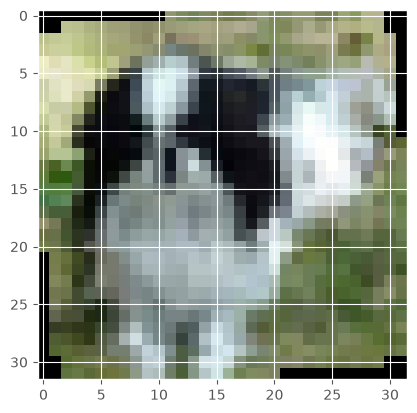

In [48]:
data_iter = iter(train_dataloader)
imgs, labels = next(data_iter)
print(labels)
print(imgs.size()) # ミニバッチ, チャネル, 高さ, 幅

img = imgs[0]
img_permute = img.permute(1, 2, 0)
img_permute = 0.5 * img_permute + 0.5
img_permute = np.clip(img_permute, 0, 1)
plt.imshow(img_permute)

In [49]:
class CNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=64,
                kernel_size=5,
                padding=2
            ),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(
                in_channels=128,
                out_channels=256,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(
                in_channels=256,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )
        self.classifier = nn.Linear(
            in_features=4*4*128,
            out_features=num_classes
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1) # 一次元のベクトル化
        x = self.classifier(x)
        return x

In [50]:
model = CNN(10)
model.to(device)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU(inplace=True)
  )
  (classifier): Linear(in_features=2048, out_features=10, bias=True)
)

In [51]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=5e-4 # L2正則化
)

In [52]:
num_epochs = 15
losses = []
accs = []
val_losses = []
val_accs = []

for epoch in range(num_epochs):
    running_loss = 0.0
    running_acc = 0.0
    for imgs, labels in train_dataloader:
        imgs = imgs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        output = model(imgs)
        loss = criterion(output, labels)
        loss.backward()
        running_loss += loss.item()
        pred = torch.argmax(output, dim=1)
        running_acc += torch.mean(pred.eq(labels).float()).item()
        optimizer.step()
    running_loss /= len(train_dataloader)
    running_acc /= len(train_dataloader)
    losses.append(running_loss)
    accs.append(running_acc)

    # validation loop
    val_running_loss = 0.0
    val_running_acc = 0.0
    for val_imgs, val_labels in validation_dataloader:
        val_imgs = val_imgs.to(device)
        val_labels = val_labels.to(device)
        val_output = model(val_imgs)
        val_loss = criterion(val_output, val_labels)
        val_running_loss += val_loss.item()
        val_pred = torch.argmax(val_output, dim=1)
        val_running_acc += torch.mean(val_pred.eq(val_labels).float()).item()
    val_running_loss /= len(validation_dataloader)
    val_running_acc /= len(validation_dataloader)

    val_losses.append(val_running_loss)
    val_accs.append(val_running_acc)
    print(
        "epoch: {}, loss: {}, acc: {}, val_loss: {}, val_acc: {}"
            .format(
                epoch,
                running_loss,
                running_acc,
                val_running_loss,
                val_running_acc
            )
    )

epoch: 0, loss: 1.4089274555540054, acc: 0.48806381957773515, val_loss: 1.0756436978666166, val_acc: 0.6201078274760383
epoch: 1, loss: 1.0076880409636715, acc: 0.643554062699936, val_loss: 0.9006623635276819, val_acc: 0.6864017571884984
epoch: 2, loss: 0.8513299828908875, acc: 0.7007957453614844, val_loss: 0.7902535616208951, val_acc: 0.7229432907348243
epoch: 3, loss: 0.7666552947906828, acc: 0.7320657389635317, val_loss: 0.7398870169354704, val_acc: 0.7413138977635783
epoch: 4, loss: 0.7114449979514551, acc: 0.7512995841330774, val_loss: 0.726977822022697, val_acc: 0.7497004792332268
epoch: 5, loss: 0.674669448546088, acc: 0.7652751119641714, val_loss: 0.7223409378109649, val_acc: 0.7516972843450479
epoch: 6, loss: 0.6457492327812155, acc: 0.7767114523352527, val_loss: 0.6759163864885276, val_acc: 0.766473642172524
epoch: 7, loss: 0.6238760155454631, acc: 0.7831893793985925, val_loss: 0.6518061561896779, val_acc: 0.7766573482428115
epoch: 8, loss: 0.6013105610720408, acc: 0.79054702

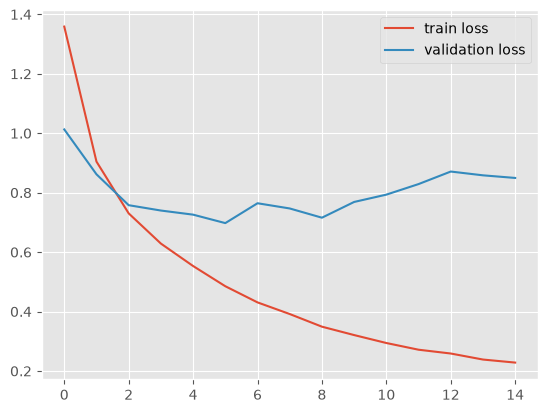

In [40]:
# データ拡張前
plt.style.use("ggplot")
plt.plot(losses, label="train loss")
plt.plot(val_losses, label="validation loss")
plt.legend()

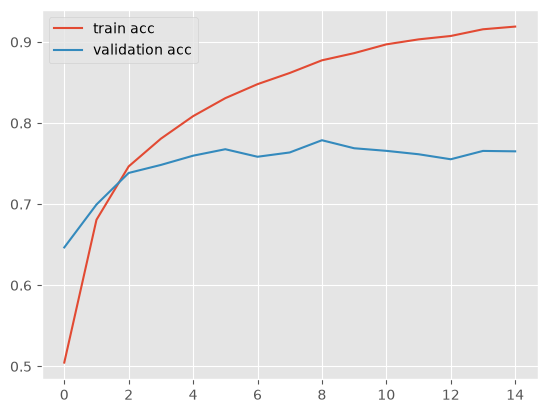

In [41]:
# データ拡張前
plt.plot(accs, label="train acc")
plt.plot(val_accs, label="validation acc")
plt.legend()

In [ ]:
# データ拡張（汎化性能を上げる）
# データ数を水増しするのが有効な手段の1つ
# 水増し時には、左右逆転、回転、明るさの変更を施したデータを追加するなど
# Pytorchでは、transformsに組み込むだけでデータ拡張を行うことができる
# ただし、エポックごとに別の画像が生成される（データ数が増えるわけではないことに注意）

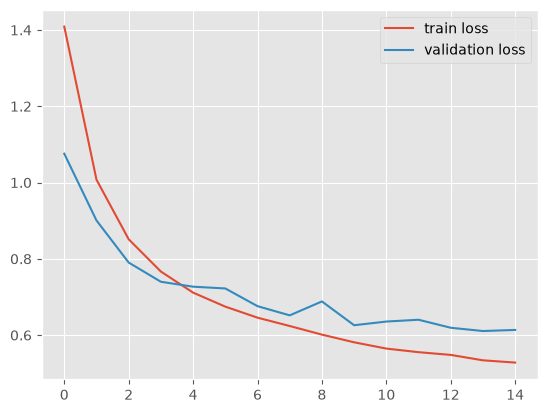

In [53]:
# データ拡張後
plt.plot(losses, label="train loss")
plt.plot(val_losses, label="validation loss")
plt.legend()

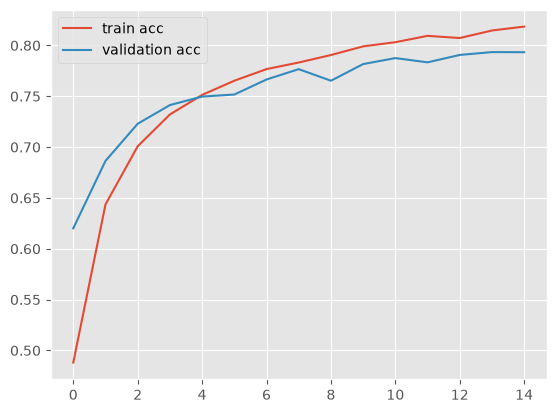

In [54]:
# データ拡張後
plt.plot(accs, label="train acc")
plt.plot(val_accs, label="validation acc")
plt.legend()